In [1]:
%pip install pandas matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# Espérance de vie et PIB

## Objectif
Étudier la relation entre le PIB et l'espérance de vie de six pays.

## Questions
- L'espérance de vie a-t-elle augmenté au fil des années ?
- Le PIB a-t-il évolué de la même façon ?
- Existe-t-il un lien entre PIB et espérance de vie ?

## Données
all_data.csv (OMS et Banque mondiale)

## Étapes
1. Chargement 2. Exploration 3. Visualisation 4. Conclusion

In [3]:
df = pd.read_csv("all_data.csv")
df.head()

,Country,Year,Life expectancy at birth (years),GDP
0,Chile,2000,77.3,7.786093e+10
1,Chile,2001,77.3,7.097992e+10
2,Chile,2002,77.8,6.973681e+10
3,Chile,2003,77.9,7.564346e+10
4,Chile,2004,78.0,9.921039e+10


In [4]:
df = df.rename(columns={"Life expectancy at birth (years)": "LEABY"})
df.head()

,Country,Year,LEABY,GDP
0,Chile,2000,77.3,7.786093e+10
1,Chile,2001,77.3,7.097992e+10
2,Chile,2002,77.8,6.973681e+10
3,Chile,2003,77.9,7.564346e+10
4,Chile,2004,78.0,9.921039e+10


In [5]:
df.info()
print(df["Country"].unique())
print(df["Year"].min(), df["Year"].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Country  96 non-null     object 
 1   Year     96 non-null     int64  
 2   LEABY    96 non-null     float64
 3   GDP      96 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 3.1+ KB
['Chile' 'China' 'Germany' 'Mexico' 'United States of America' 'Zimbabwe']
2000 2015


In [6]:
df.describe()

,Year,LEABY,GDP
count,96.000000,96.000000,9.600000e+01
mean,2007.500000,72.789583,3.880499e+12
std,4.633971,10.672882,5.197561e+12
min,2000.000000,44.300000,4.415703e+09
25%,2003.750000,74.475000,1.733018e+11
50%,2007.500000,76.750000,1.280220e+12
75%,2011.250000,78.900000,4.067510e+12
max,2015.000000,81.000000,1.810000e+13


In [7]:
df.groupby("Country")[["LEABY", "GDP"]].mean()

,LEABY,GDP
Country,,
Chile,78.94375,1.697888e+11
China,74.26250,4.957714e+12
Germany,79.65625,3.094776e+12
Mexico,75.71875,9.766506e+11
United States of America,78.06250,1.407500e+13
Zimbabwe,50.09375,9.062580e+09


In [8]:
df["GDP_milliards"] = df["GDP"] / 1e9
df.groupby("Country")[["LEABY", "GDP_milliards"]].mean().round(1)

,LEABY,GDP_milliards
Country,,
Chile,78.9,169.8
China,74.3,4957.7
Germany,79.7,3094.8
Mexico,75.7,976.7
United States of America,78.1,14075.0
Zimbabwe,50.1,9.1


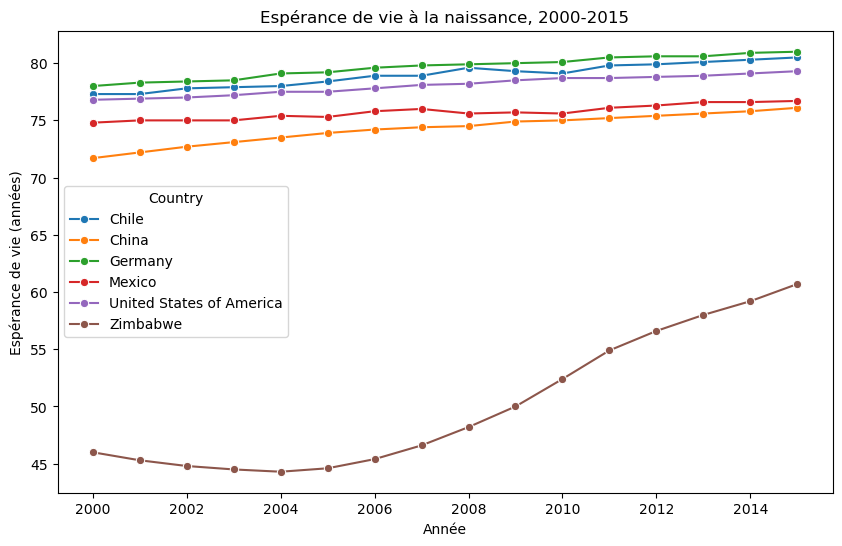

In [9]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="Year", y="LEABY", hue="Country", marker="o")
plt.title("Espérance de vie à la naissance, 2000-2015")
plt.xlabel("Année")
plt.ylabel("Espérance de vie (années)")
plt.savefig("images/esperance_vie.png", dpi=150, bbox_inches="tight")
plt.show()

Tous les pays progressent entre 2000 et 2015, mais à des rythmes très différents.
Le Zimbabwe est à part : environ 46 ans en 2000, une baisse jusqu’à environ 44 ans en 2004, puis une forte remontée jusqu’à environ 61 ans en 2015. Il gagne plus de 15 ans en dix ans, mais reste environ 20 ans en dessous des autres.
La Chine est le deuxième pays qui progresse le plus : de 72 à 76 ans environ.
L’Allemagne et le Chili restent en tête, autour de 80 ans, avec des courbes très proches.
Les États-Unis progressent lentement et restent sous l’Allemagne et le Chili, malgré le PIB le plus élevé.

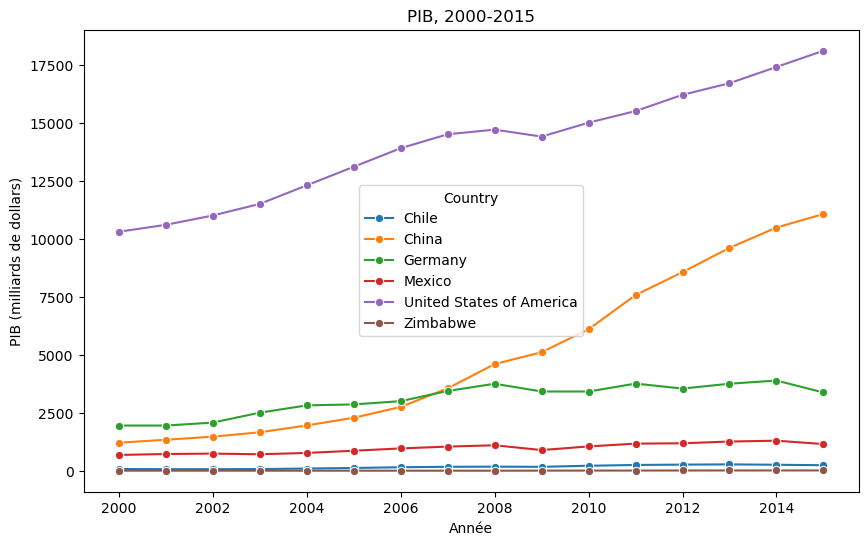

In [10]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="Year", y="GDP_milliards", hue="Country", marker="o")
plt.title("PIB, 2000-2015")
plt.xlabel("Année")
plt.ylabel("PIB (milliards de dollars)")
plt.savefig("images/pib.png", dpi=150, bbox_inches="tight")
plt.show()

Les États-Unis dominent : d’environ 10 300 à 18 100 milliards de dollars.
La Chine a la croissance la plus spectaculaire : d’environ 1 200 à 11 000 milliards. Elle dépasse l’Allemagne vers 2007 et devient deuxième économie du groupe.
L’Allemagne progresse jusqu’en 2008 environ, puis stagne autour de 3 500 milliards.
Le Mexique, le Chili et le Zimbabwe semblent plats, mais ce n’est qu’un effet d’échelle : leurs PIB sont si petits devant ceux des États-Unis qu’on ne voit plus leur évolution.
Plusieurs courbes (États-Unis, Allemagne, Mexique) fléchissent vers 2009, ce qui correspond à la crise financière.

À la différence de l’espérance de vie, le Zimbabwe n’a pas de creux visible vers 2004 sur ce graphique, mais on ne peut pas le vérifier à cette échelle. Le PIB et l’espérance de vie ne suivent donc pas forcément la même trajectoire.

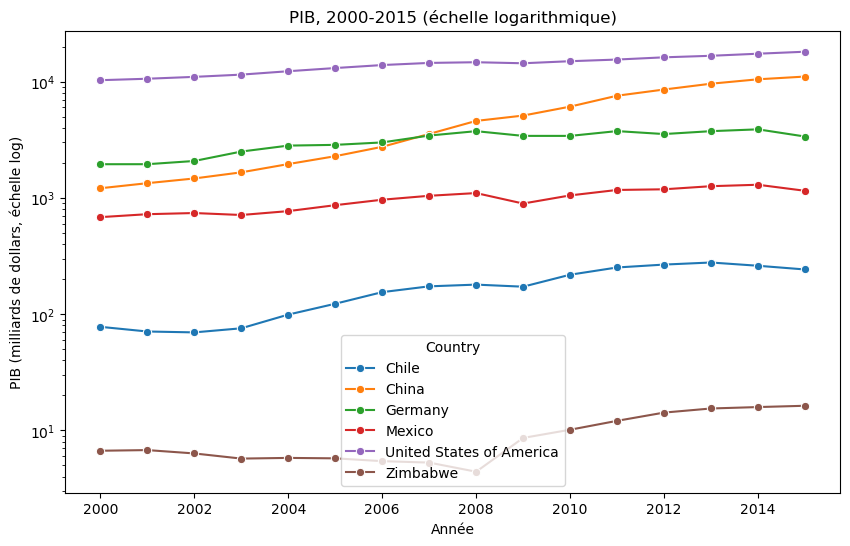

In [11]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="Year", y="GDP_milliards", hue="Country", marker="o")
plt.yscale("log")
plt.title("PIB, 2000-2015 (échelle logarithmique)")
plt.xlabel("Année")
plt.ylabel("PIB (milliards de dollars, échelle log)")
plt.savefig("images/PIB_Echelle_log.png", dpi=150, bbox_inches="tight")
plt.show()

Zimbabwe : le PIB baisse de 2000 à 2008 (d’environ 6,6 à 4,4 milliards), puis remonte nettement jusqu’à environ 16 milliards en 2015.
Chili : un creux autour de 2001-2002, puis une forte hausse jusqu’à 2013 (de 70 à près de 280 milliards).
Mexique : un net recul en 2009, qui correspond à la crise financière.
Chine : une croissance régulière, la plus rapide en proportion pour les grandes économies.

À partir de ces graphiques, on voit que le Zimbabwe a d’abord vu son espérance de vie remonter (dès 2004), puis son PIB (après 2008). Les deux courbes ne coïncident donc pas dans le temps, ce qui nuance l’idée que la richesse seule explique la santé. 

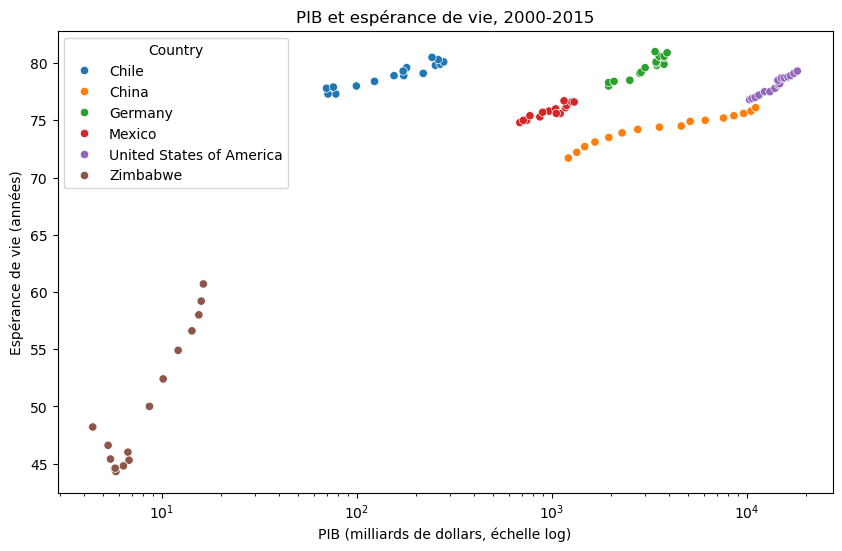

In [12]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="GDP_milliards", y="LEABY", hue="Country")
plt.xscale("log")
plt.title("PIB et espérance de vie, 2000-2015")
plt.xlabel("PIB (milliards de dollars, échelle log)")
plt.ylabel("Espérance de vie (années)")
plt.savefig("images/nuage.png", dpi=150, bbox_inches="tight")
plt.show()

Chaque pays forme sa propre trajectoire : en montant dans le temps, le PIB et l’espérance de vie augmentent ensemble. La relation est positive à l’intérieur de chaque pays.
Le Zimbabwe est le plus frappant : une pente très raide. Un petit gain de PIB va de pair avec un gain d’espérance de vie de plus de 15 ans.
Les cinq autres pays forment des nuages presque horizontaux. Passer de 1 000 à 10 000 milliards de PIB (la Chine) ne rajoute que quelques années d’espérance de vie.
Entre pays, le lien n’est pas régulier : les États-Unis ont un PIB bien supérieur à l’Allemagne et au Chili, mais une espérance de vie plus basse.

La relation est donc forte quand le niveau de vie est très bas, puis elle s’aplatit : c’est un effet de rendements décroissants.

In [13]:
print(df["GDP_milliards"].corr(df["LEABY"]))

0.34320674844915594


Ce que signifie 0,34

C’est la corrélation sur l’ensemble des 96 points, avec le PIB en valeur brute. Elle est faible à modérée (0 = aucun lien, 1 = lien parfait), alors que le nuage de points montrait une relation nette dans chaque pays.

Deux raisons expliquent cet écart :

Les valeurs extrêmes du PIB (États-Unis, Chine) écrasent le calcul : la corrélation mesure une droite, et le lien est ici courbe, avec des rendements décroissants.
Le Zimbabwe a un PIB minuscule et une espérance de vie très basse, mais les autres pays sont tous groupés en haut du graphique, ce qui brouille le calcul global.

Cette valeur illustre un piège classique : une corrélation globale faible n’implique pas l’absence de relation.

In [15]:

df["log_GDP"] = np.log10(df["GDP_milliards"])

print("Globale :", round(df["log_GDP"].corr(df["LEABY"]), 2))
print(df.groupby("Country")[["log_GDP", "LEABY"]].apply(lambda g: g["log_GDP"].corr(g["LEABY"])).round(2))

Globale : 0.79
Country
Chile                       0.95
China                       0.97
Germany                     0.93
Mexico                      0.93
United States of America    0.98
Zimbabwe                    0.94
dtype: float64


Ces chiffres montrent que les deux variables évoluent ensemble, pas que l’une cause l’autre. Comme les deux augmentent avec le temps, elles sont mécaniquement corrélées. D’autres facteurs ont pu jouer : l’accès aux soins, la lutte contre les maladies, l’éducation. Le Zimbabwe en est un bon exemple, car son espérance de vie remonte avant son PIB.

In [ ]:
# Conclusions

## Ce que j'ai fait
J'ai chargé les données de l'OMS et de la Banque mondiale (`all_data.csv`) sur six pays (Chili, Chine, Allemagne, Mexique, États-Unis, Zimbabwe) entre 2000 et 2015. Je les ai explorées avec pandas, puis représentées avec seaborn et Matplotlib : évolution de l'espérance de vie, évolution du PIB (en échelle linéaire puis logarithmique), nuage de points PIB et espérance de vie, et corrélations.

## Ce que j'ai trouvé
- **L'espérance de vie a augmenté dans les six pays** entre 2000 et 2015.
- **Le Zimbabwe progresse le plus** (d'environ 46 à 61 ans) après une baisse jusqu'en 2004, mais reste environ 20 ans en dessous des autres pays.
- **La Chine a la plus forte croissance du PIB** (d'environ 1 200 à 11 000 milliards de dollars) et dépasse l'Allemagne vers 2007.
- **Un PIB plus élevé ne garantit pas une espérance de vie plus longue** : les États-Unis ont le PIB le plus élevé, mais une espérance de vie inférieure à celle de l'Allemagne et du Chili.
- **Le PIB et l'espérance de vie évoluent ensemble.** La corrélation est de 0,79 sur l'ensemble des pays (avec le PIB en logarithme) et d'au moins 0,93 pour chaque pays pris séparément. Avec le PIB brut, elle tombe à 0,34, parce que la relation n'est pas linéaire.
- **Les rendements sont décroissants** : pour un pays à faible PIB, un petit gain de richesse va de pair avec un grand gain d'espérance de vie, alors que pour un pays riche, l'effet est faible.
- Au Zimbabwe, l'espérance de vie remonte dès 2004, **avant** la reprise du PIB (après 2008).

## Limites
- Seulement six pays et seize années : les résultats ne se généralisent pas à tous les pays.
- **Corrélation n'est pas causalité** : le PIB et l'espérance de vie augmentent tous deux avec le temps, ce qui les corrèle mécaniquement. D'autres facteurs (accès aux soins, lutte contre les maladies, éducation) n'ont pas été étudiés.
- Le PIB total ne tient pas compte de la taille de la population : le PIB par habitant serait plus pertinent pour comparer les pays.